# PRCP-1001: Rice Leaf Disease Detection Using CNN

**DataMites Capstone Project**

## Requirements
- Perform complete exploratory data analysis.
- Classify the three disease classes found in the supplied dataset.
- Analyze data augmentation.
- Compare multiple models and recommend a production candidate.
- Document challenges and solutions.

The brief says there are 120 JPG images (40 per class). It names Leaf smut, Brown spot and Bacterial leaf blight in the dataset description, while the problem statement names leaf blast, bacterial blight and brown spot. This notebook checks the actual folder names and does not silently relabel classes.

**Caution:** 120 images is a very small dataset. Results are educational/exploratory, not proof of field-ready performance.

## 1. Imports and reproducibility

In [1]:
# If needed, run: %pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow
import os, random, time, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

C:\Users\V.R.LAKSHMI PRASANNA\AppData\Roaming\Python\Python39\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\V.R.LAKSHMI PRASANNA\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (
C:\Users\V.R.LAKSHMI PRASANNA\anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


TensorFlow: 2.20.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Download and extract dataset
Dataset URL supplied in the brief. The notebook downloads the ZIP into `data/` automatically.

In [2]:
DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"
DATA_DIR = Path.cwd() / "data"
ZIP_PATH = DATA_DIR / "RiceLeaf.zip"
DATA_DIR.mkdir(exist_ok=True)

if not ZIP_PATH.exists():
    try:
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception as e:
        print("Download failed:", e)
        print("Download the ZIP manually from DATA_URL and place it at:", ZIP_PATH.resolve())

if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Extracted to:", DATA_DIR.resolve())

for p in DATA_DIR.iterdir():
    print(p.name)

Extracted to: C:\Users\V.R.LAKSHMI PRASANNA\Desktop\data
Data
RiceLeaf.zip


## 3. Find class folders and build image inventory

In [7]:

import os
import pandas as pd
from pathlib import Path
from PIL import Image

DATA_DIR = Path.cwd() / "data"

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find all images recursively
image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTS
]

rows = []

for img_path in image_paths:

    # Use the immediate parent folder as class name
    class_name = img_path.parent.name

    rows.append({
        "filepath": str(img_path.resolve()),
        "class_name": class_name
    })

image_df = pd.DataFrame(rows)

print("Total images:", len(image_df))
print("\nClass distribution:")
print(image_df["class_name"].value_counts())

print("\nDataset shape:", image_df.shape)

display(image_df.head())

# Check image dimensions
image_info = []

for path in image_df["filepath"]:

    with Image.open(path) as img:
        image_info.append({
            "width": img.width,
            "height": img.height,
            "mode": img.mode
        })

image_info_df = pd.DataFrame(image_info)

print("\nImage dimensions:")
display(image_info_df.describe())


Total images: 119

Class distribution:
class_name
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64

Dataset shape: (119, 2)


,filepath,class_name
0,C:\Users\V.R.LAKSHMI PRASANNA\Desktop\data\Bac...,Bacterial leaf blight
1,C:\Users\V.R.LAKSHMI PRASANNA\Desktop\data\Bac...,Bacterial leaf blight
2,C:\Users\V.R.LAKSHMI PRASANNA\Desktop\data\Bac...,Bacterial leaf blight
3,C:\Users\V.R.LAKSHMI PRASANNA\Desktop\data\Bac...,Bacterial leaf blight
4,C:\Users\V.R.LAKSHMI PRASANNA\Desktop\data\Bac...,Bacterial leaf blight



Image dimensions:


,width,height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


## 4. Exploratory data analysis and quality checks

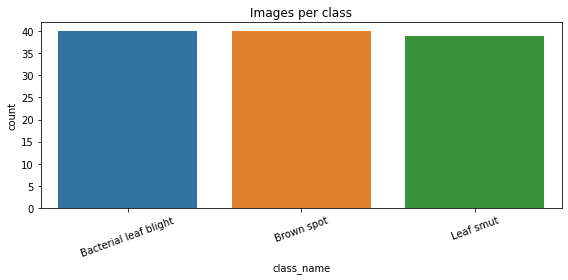

Readable: 119 Unreadable: 0


,width,height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


Color modes:


mode
RGB    119
Name: count, dtype: int64

Formats:


format
JPEG    119
Name: count, dtype: int64

C:\Users\V.R.LAKSHMI PRASANNA\AppData\Roaming\Python\Python39\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\V.R.LAKSHMI PRASANNA\AppData\Roaming\Python\Python39\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


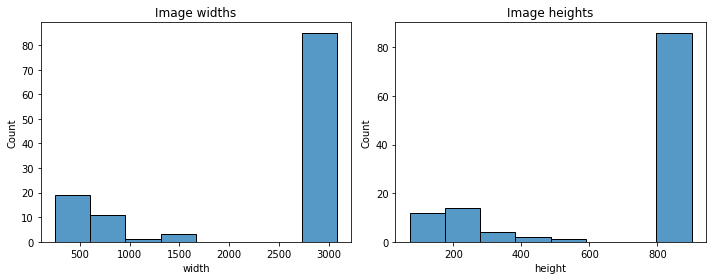

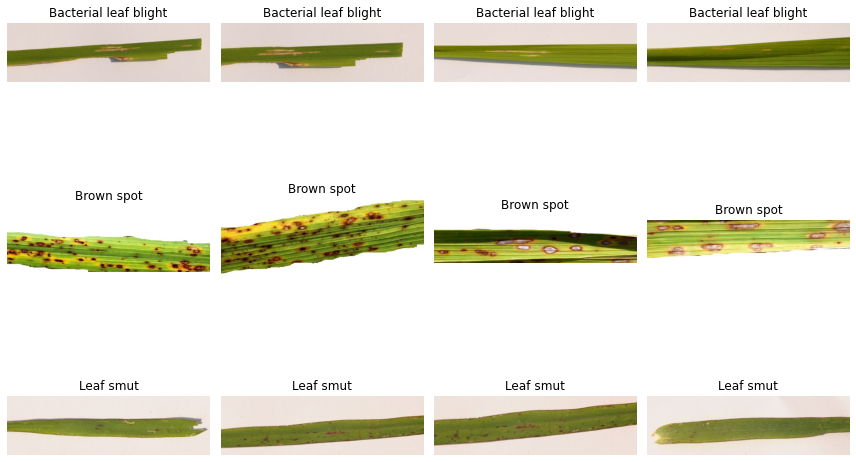

In [8]:
plt.figure(figsize=(8,4))
sns.countplot(data=image_df, x="class_name", order=image_df["class_name"].value_counts().index)
plt.title("Images per class"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

quality, bad = [], []
for r in image_df.itertuples(index=False):
    try:
        with Image.open(r.filepath) as im:
            quality.append({"filepath":r.filepath, "class_name":r.class_name, "width":im.width, "height":im.height, "mode":im.mode, "format":im.format})
    except (UnidentifiedImageError, OSError, ValueError) as e:
        bad.append({"filepath":r.filepath, "error":str(e)})
quality_df, bad_df = pd.DataFrame(quality), pd.DataFrame(bad)
print("Readable:", len(quality_df), "Unreadable:", len(bad_df))
if not bad_df.empty: display(bad_df.head())
display(quality_df[["width","height"]].describe())
print("Color modes:"); display(quality_df["mode"].value_counts())
print("Formats:"); display(quality_df["format"].value_counts())

fig, ax = plt.subplots(1,2,figsize=(10,4))
sns.histplot(quality_df["width"], ax=ax[0]); ax[0].set_title("Image widths")
sns.histplot(quality_df["height"], ax=ax[1]); ax[1].set_title("Image heights")
plt.tight_layout(); plt.show()

class_labels = sorted(image_df.class_name.unique())
fig, axes = plt.subplots(len(class_labels), 4, figsize=(12, 3*len(class_labels)))
axes = np.array(axes).reshape(len(class_labels),4)
for i, label in enumerate(class_labels):
    examples = image_df[image_df.class_name == label].head(4)
    for j in range(4):
        axes[i,j].axis("off")
        if j < len(examples):
            with Image.open(examples.iloc[j].filepath) as im: axes[i,j].imshow(im.convert("RGB"))
            axes[i,j].set_title(label)
plt.tight_layout(); plt.show()

## 5. Label encoding and stratified train/validation/test split
The test set is held back. Augmentation is applied only to training images to avoid leakage.

In [9]:
bad_paths = set(bad_df.filepath) if not bad_df.empty else set()
clean_df = image_df[~image_df.filepath.isin(bad_paths)].copy().reset_index(drop=True)
encoder = LabelEncoder()
clean_df["label"] = encoder.fit_transform(clean_df.class_name)
CLASS_NAMES = list(encoder.classes_)
N_CLASSES = len(CLASS_NAMES)
train_val, test_df = train_test_split(clean_df, test_size=.20, random_state=SEED, stratify=clean_df.label)
train_df, val_df = train_test_split(train_val, test_size=.25, random_state=SEED, stratify=train_val.label)
print("Classes:", CLASS_NAMES)
print("Train/validation/test:", len(train_df), len(val_df), len(test_df))
for title, frame in [("Train",train_df),("Validation",val_df),("Test",test_df)]:
    print(title); display(frame.class_name.value_counts().reindex(CLASS_NAMES,fill_value=0))

Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Train/validation/test: 71 24 24
Train


class_name
Bacterial leaf blight    24
Brown spot               24
Leaf smut                23
Name: count, dtype: int64

Validation


class_name
Bacterial leaf blight    8
Brown spot               8
Leaf smut                8
Name: count, dtype: int64

Test


class_name
Bacterial leaf blight    8
Brown spot               8
Leaf smut                8
Name: count, dtype: int64

## 6. Image preprocessing and data augmentation

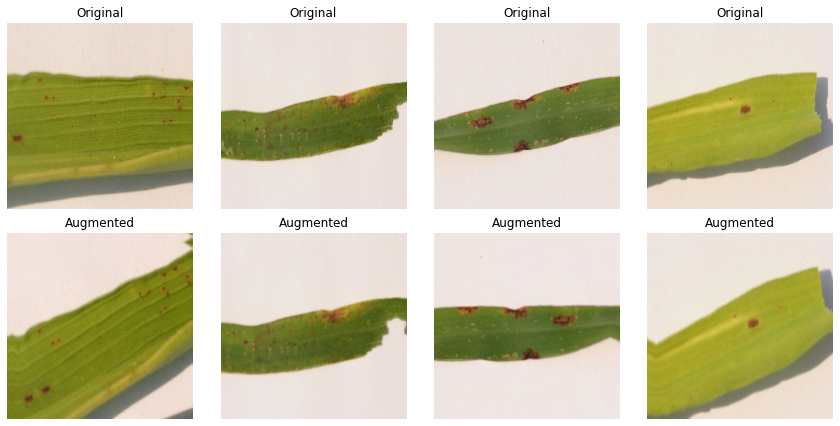

In [10]:
IMG_SIZE = (224,224)
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None,None,3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(label,tf.int32)

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.filepath.values, frame.label.values.astype("int32")))
    if training: ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df,True), make_ds(val_df), make_ds(test_df)
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(.08),
    layers.RandomZoom(.10),
    layers.RandomTranslation(.08,.08),
    layers.RandomContrast(.10)
], name="augmentation")

for x,y in train_ds.take(1):
    xa = augment(x, training=True)
    n = min(4, x.shape[0])
    fig, ax = plt.subplots(2,n,figsize=(3*n,6))
    for i in range(n):
        ax[0,i].imshow(x[i].numpy()); ax[0,i].set_title("Original"); ax[0,i].axis("off")
        ax[1,i].imshow(tf.clip_by_value(xa[i],0,1).numpy()); ax[1,i].set_title("Augmented"); ax[1,i].axis("off")
    plt.tight_layout(); plt.show()
    break

## 7. Model architectures
Models: baseline CNN, CNN with augmentation, MobileNetV2 transfer learning and EfficientNetB0 transfer learning. Transfer learning requires pretrained weights to be available locally or downloadable.

In [13]:
def build_cnn(use_augmentation=False):
    inp = keras.Input((*IMG_SIZE,3)); x = inp
    if use_augmentation: x = augment(x)
    for filters in [32,64,128]:
        x = layers.Conv2D(filters,3,padding="same",activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(.35)(x)
    x = layers.Dense(64,activation="relu")(x)
    x = layers.Dropout(.25)(x)
    out = layers.Dense(N_CLASSES,activation="softmax")(x)
    return keras.Model(inp,out)

def build_transfer(name):
    inp = keras.Input((*IMG_SIZE,3))
    x = layers.Rescaling(255.0)(inp)
    if name == "MobileNetV2":
        x = keras.applications.mobilenet_v2.preprocess_input(x)
        backbone = keras.applications.MobileNetV2(include_top=False,weights="imagenet",input_shape=(*IMG_SIZE,3))
    elif name == "EfficientNetB0":
        backbone = keras.applications.EfficientNetB0(include_top=False,weights="imagenet",input_shape=(*IMG_SIZE,3))
    else: raise ValueError(name)
    backbone.trainable = False
    x = backbone(x,training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(.3)(x)
    out = layers.Dense(N_CLASSES,activation="softmax")(x)
    return keras.Model(inp,out)

def callbacks_for(key):
    Path("models").mkdir(exist_ok=True)
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.3,patience=3,min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(f"models/{key}_best.keras",monitor="val_loss",save_best_only=True)
    ]

## 8. Train models

In [14]:
EPOCHS = 30
models, histories, train_seconds = {}, {}, {}

def fit_model(key, model):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=callbacks_for(key), verbose=1)
    train_seconds[key] = time.time()-start
    models[key], histories[key] = model, history
    return model

fit_model("baseline_cnn", build_cnn(False))
fit_model("augmented_cnn", build_cnn(True))

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 16s 661ms/step - accuracy: 0.3453 - loss: 1.1081 - val_accuracy: 0.3750 - val_loss: 1.0994 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 639ms/step - accuracy: 0.6450 - loss: 0.9138 - val_accuracy: 0.3333 - val_loss: 1.0982 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 594ms/step - accuracy: 0.7270 - loss: 0.6981 - val_accuracy: 0.2917 - val_loss: 1.1008 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 557ms/step - accuracy: 0.7381 - loss: 0.6585 - val_accuracy: 0.3333 - val_loss: 1.1041 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 574ms/step - accuracy: 0.5692 - loss: 0.8720 - val_accuracy: 0.3333 - val_loss: 1.1177 - learning_rate: 0.0010
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 558ms/step - accuracy: 0.7027 - loss: 0.6752 - val_accuracy: 0.2917 - val_loss: 1.1201 - learning_rate: 3.0000e-04
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 577ms/step - accuracy: 0.7396 - loss: 0.6044 - val_accu

<Functional name=functional_2, built=True>

In [15]:
# Optional pretrained models. If weights cannot be downloaded, CNN models remain available.
for name, key in [("MobileNetV2","mobilenetv2"),("EfficientNetB0","efficientnetb0")]:
    try:
        fit_model(key, build_transfer(name))
    except Exception as e:
        print(name, "could not be trained:", repr(e))
        print("Check internet access / cached ImageNet weights.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 20s 955ms/step - accuracy: 0.2623 - loss: 1.6081 - val_accuracy: 0.5000 - val_loss: 1.1721 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 446ms/step - accuracy: 0.4563 - loss: 1.0784 - val_accuracy: 0.7083 - val_loss: 0.8390 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 443ms/step - accuracy: 0.6747 - loss: 0.6980 - val_accuracy: 0.8333 - val_loss: 0.6705 - learning_rate: 0.0010
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 442ms/step - accuracy: 0.7684 - loss: 0.5210 - val_accuracy: 0.8750 - val_loss: 0.5763 - learning_rate: 0.0010
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 455ms/step - accuracy: 0.8544 - loss: 0.5392 - val_accuracy: 0.8750 - val_loss: 0.5016 - learning_rate: 0.0010
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 465ms/step - accuracy: 0.9237 - loss: 0.3168 - val_accuracy: 0.8333 - val_loss: 0.4727 - learning_rate: 0.0010
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 450ms/step 

Epoch 13/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 710ms/step - accuracy: 0.9650 - loss: 0.2132 - val_accuracy: 0.8750 - val_loss: 0.3470 - learning_rate: 0.0010
Epoch 14/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 736ms/step - accuracy: 0.9820 - loss: 0.1855 - val_accuracy: 0.8750 - val_loss: 0.3007 - learning_rate: 0.0010
Epoch 15/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 741ms/step - accuracy: 0.9726 - loss: 0.1500 - val_accuracy: 0.8750 - val_loss: 0.2921 - learning_rate: 0.0010
Epoch 16/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 708ms/step - accuracy: 0.9570 - loss: 0.1739 - val_accuracy: 0.8750 - val_loss: 0.2870 - learning_rate: 0.0010
Epoch 17/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 424ms/step - accuracy: 1.0000 - loss: 0.1294 - val_accuracy: 0.8750 - val_loss: 0.2892 - learning_rate: 0.0010
Epoch 18/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 708ms/step - accuracy: 1.0000 - loss: 0.1462 - val_accuracy: 0.8750 - val_loss: 0.2791 - learning_rate: 0.0010
Epoch 19/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 11s 760ms/step - accuracy: 0.9757 - loss: 0.1460 - val_ac

## 9. Training curves

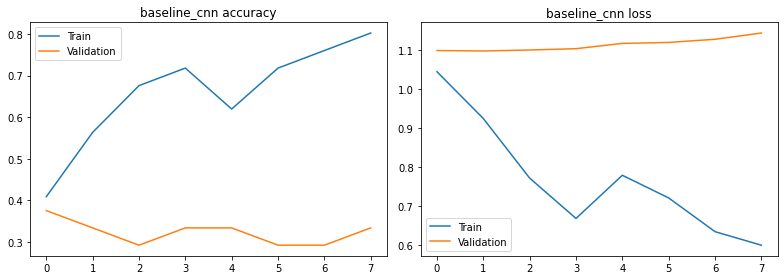

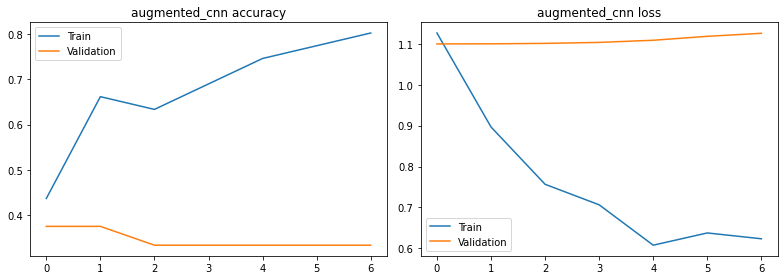

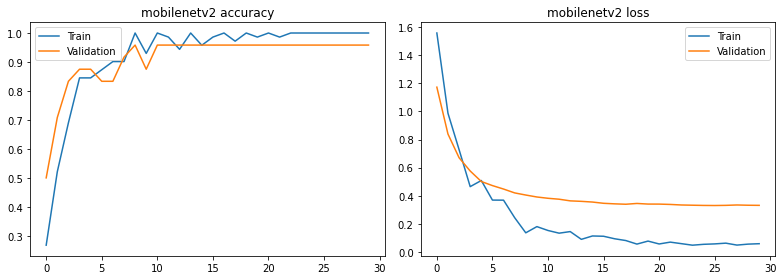

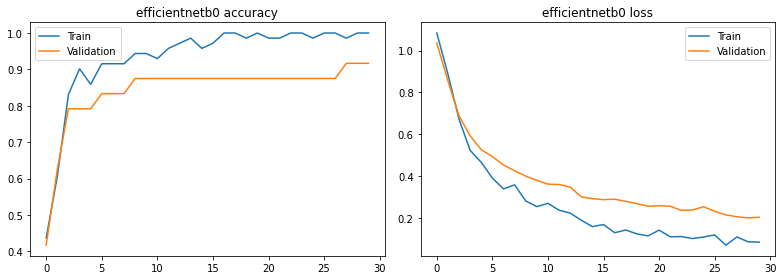

In [16]:
for key, h in histories.items():
    hist = pd.DataFrame(h.history)
    fig, ax = plt.subplots(1,2,figsize=(11,4))
    ax[0].plot(hist.accuracy,label="Train"); ax[0].plot(hist.val_accuracy,label="Validation")
    ax[0].set_title(key+" accuracy"); ax[0].legend()
    ax[1].plot(hist.loss,label="Train"); ax[1].plot(hist.val_loss,label="Validation")
    ax[1].set_title(key+" loss"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 10. Test evaluation and model comparison

\n baseline_cnn
                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         8
           Brown spot       0.33      1.00      0.50         8
            Leaf smut       0.00      0.00      0.00         8

             accuracy                           0.33        24
            macro avg       0.11      0.33      0.17        24
         weighted avg       0.11      0.33      0.17        24



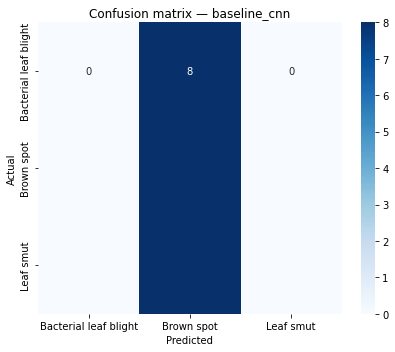

\n augmented_cnn
                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         8
           Brown spot       0.33      1.00      0.50         8
            Leaf smut       0.00      0.00      0.00         8

             accuracy                           0.33        24
            macro avg       0.11      0.33      0.17        24
         weighted avg       0.11      0.33      0.17        24



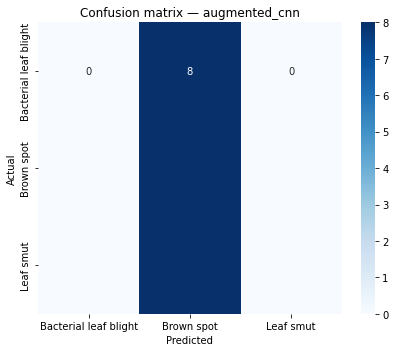

\n mobilenetv2
                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      1.00      0.89         8
           Brown spot       1.00      0.88      0.93         8
            Leaf smut       1.00      0.88      0.93         8

             accuracy                           0.92        24
            macro avg       0.93      0.92      0.92        24
         weighted avg       0.93      0.92      0.92        24



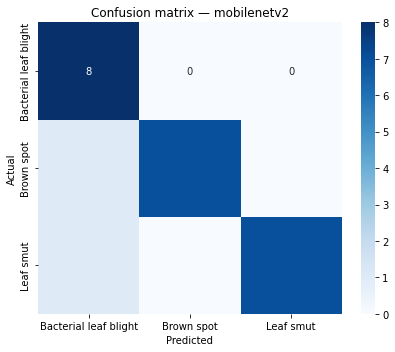

\n efficientnetb0
                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      1.00      0.89         8
           Brown spot       1.00      0.75      0.86         8
            Leaf smut       1.00      1.00      1.00         8

             accuracy                           0.92        24
            macro avg       0.93      0.92      0.92        24
         weighted avg       0.93      0.92      0.92        24



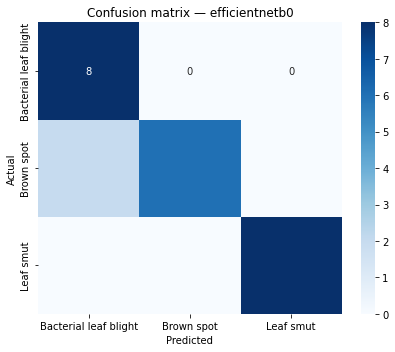

,model,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds
0,mobilenetv2,0.916667,0.933333,0.916667,0.918519,144.185883
1,efficientnetb0,0.916667,0.933333,0.916667,0.915344,220.942063
2,baseline_cnn,0.333333,0.111111,0.333333,0.166667,58.252824
3,augmented_cnn,0.333333,0.111111,0.333333,0.166667,55.324518


In [17]:
def evaluate(key, model):
    y_true, y_pred = [], []
    for images, labels in test_ds:
        probs = model.predict(images,verbose=0)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(np.argmax(probs,axis=1).tolist())
    print("\\n",key)
    print(classification_report(y_true,y_pred,labels=list(range(N_CLASSES)),target_names=CLASS_NAMES,zero_division=0))
    cm = confusion_matrix(y_true,y_pred,labels=list(range(N_CLASSES)))
    plt.figure(figsize=(6,5))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES)
    plt.title("Confusion matrix — "+key); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout(); plt.show()
    return {
        "model":key,
        "accuracy":accuracy_score(y_true,y_pred),
        "precision_macro":precision_score(y_true,y_pred,average="macro",zero_division=0),
        "recall_macro":recall_score(y_true,y_pred,average="macro",zero_division=0),
        "f1_macro":f1_score(y_true,y_pred,average="macro",zero_division=0),
        "training_time_seconds":train_seconds.get(key,np.nan)
    }

comparison_df = pd.DataFrame([evaluate(k,m) for k,m in models.items()])
comparison_df = comparison_df.sort_values("f1_macro",ascending=False).reset_index(drop=True)
display(comparison_df)

## 11. Data augmentation experiment

In [ ]:
if {"baseline_cnn","augmented_cnn"}.issubset(set(comparison_df.model)):
    display(comparison_df[comparison_df.model.isin(["baseline_cnn","augmented_cnn"])].set_index("model"))
else:
    print("Both CNN models are required for the augmentation comparison.")

## 12. Hyperparameter notes

Initial configuration: 224×224 images, batch size 8, Adam optimizer, learning rate 0.001, maximum 30 epochs, early stopping patience 6, dropout 0.25–0.35. With so few images, extensive tuning may overfit the validation set. Record any additional experiments and leave the test set untouched until final evaluation.

## 13. Predict a new rice-leaf image

In [18]:
best_model = models[comparison_df.iloc[0].model] if not comparison_df.empty else None
best_model_name = comparison_df.iloc[0].model if not comparison_df.empty else None
print("Best by test macro F1:",best_model_name)

def predict_rice_leaf(image_path):
    if best_model is None: raise RuntimeError("Train a model first.")
    img = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    arr = np.asarray(img,dtype=np.float32)/255.0
    probs = best_model.predict(arr[np.newaxis,...],verbose=0)[0]
    idx = int(np.argmax(probs))
    plt.figure(figsize=(5,5)); plt.imshow(img); plt.axis("off")
    plt.title(f"{CLASS_NAMES[idx]} — confidence {probs[idx]:.1%}"); plt.show()
    return {"predicted_class":CLASS_NAMES[idx],"confidence":float(probs[idx]),
            "probabilities":dict(zip(CLASS_NAMES,probs.astype(float)))}

# Example:
# print(predict_rice_leaf(test_df.iloc[0].filepath))

Best by test macro F1: mobilenetv2


## 14. Challenges and solutions report

Complete the evidence column after running the notebook; do not claim an improvement unless the output supports it.

| Challenge | Technique | Reason | Evidence to record |
|---|---|---|---|
| Very small dataset | Transfer learning and careful augmentation | Reuse learned visual features and vary training examples | Actual validation/test metrics |
| Overfitting | Dropout, early stopping, augmentation | Reduce memorization | Training/validation curves |
| Different image dimensions | Resize all images | CNN requires consistent input shape | Dimension summary |
| Different color modes | Convert all images to RGB | Consistent 3-channel input | Mode counts |
| Corrupted files | Detect and exclude while reporting | Avoid read failures | Number of unreadable files |
| Class imbalance, if present | Stratified splitting; inspect counts | Preserve class proportions | Class distribution chart |
| Limited compute / pretrained weights | Use custom CNN or cached weights | Keep notebook runnable | Runtime and errors |

## 15. Production recommendation

Use the measured macro F1, class-wise recall, inference time, model size and stability when choosing a candidate. Do not select a model on accuracy alone. This 120-image dataset is not sufficient to establish production readiness. A real deployment requires a much larger expert-labelled dataset, independent field testing across farms/seasons/devices, specialist validation, confidence calibration and a safe path for uncertain predictions.

## 16. Conclusion

After running all cells, summarize the actual image counts, EDA findings, model metrics, augmentation impact, best model and observed challenges. Do not invent accuracy values or results. Treat the model as an academic prototype until validated on substantially more real-world images.

In [19]:
# Save measured comparison table
Path("results").mkdir(exist_ok=True)
if not comparison_df.empty:
    comparison_df.to_csv("results/model_comparison.csv",index=False)
    print("Saved results/model_comparison.csv")
else:
    print("No results to export.")

Saved results/model_comparison.csv
